# Airbnb no Rio de Janeiro: os pequenos anfitriões conseguem competir?
**Projeto aplicado – Marketing Digital / Ciência de Dados (CEUB) · Metodologia CRISP-DM**

**Fonte dos dados:** Inside Airbnb (insideairbnb.com), arquivo `listings.csv.gz` (*Detailed Listings data*) do Rio de Janeiro, publicado em **22/09/2026** (coleta feita entre 23 e 29/09/2026).

**Como rodar (Google Colab):** clique no ícone de pasta à esquerda, faça upload do arquivo `listings.csv.gz` (não precisa descompactar) e execute as células na ordem (*Ambiente de execução → Executar tudo*).

Roteiro do notebook:
1. Compreensão do Negócio
2. Compreensão dos Dados
3. Preparação dos Dados
4. Modelagem
5. Avaliação
6. Impacto social e inovação
7. Implantação
8. Considerações finais

---
## Fase 1 – Compreensão do Negócio

**Contexto.** O Airbnb se apresenta como uma plataforma em que pessoas comuns alugam um quarto ou o próprio imóvel para complementar a renda. No Rio, porém, parte da oferta está nas mãos de gestores profissionais com dezenas de anúncios.

**Problema.** Os anfitriões individuais (aqueles que têm um único anúncio) recebem menos reservas que os profissionais. A questão é por quê, e o que a plataforma pode fazer a respeito. Se for por pior qualidade, a resposta é uma; se for por falta de visibilidade ou de selos de confiança, é outra, e o marketing pode agir nela.

**Objetivo.** Identificar quais fatores estão associados à ocupação de um anúncio (noites reservadas no ano) e verificar se ser um anfitrião individual, em si, reduz a ocupação depois de considerar preço, tipo de imóvel, bairro, nota e selo Superhost.

**Critérios de sucesso (definidos antes da análise):**

| Tipo | Critério | Meta |
|---|---|---|
| Negócio | Explicar por que os individuais têm menos reservas | uma causa provável, sobre a qual o marketing possa agir |
| Negócio | Propor uma ação de marketing acionável | público, canal, recursos e risco definidos |
| Negócio | Deixar o resultado acompanhável | 3 ou mais indicadores com linha de base |
| Dados | Medir a concentração do mercado | % por tipo de anfitrião e bairro |
| Dados | Modelo com poder explicativo útil | R² ≥ 0,25 no teste |
| Dados | Comparar algoritmos | pelo menos 2 |

In [1]:
# Bibliotecas
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

# Cores fixas por tipo de anfitrião (mesma cor em todos os gráficos)
CORES = {'Individual (1 anúncio)': '#2a78d6',
         'Pequeno (2 a 5)': '#eb6834',
         'Profissional (6 ou mais)': '#1baf7a'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'axes.axisbelow': True})

---
## Fase 2 – Compreensão dos Dados
### 2.1 Coleta inicial

In [2]:
df = pd.read_csv('listings.csv.gz')   # o pandas lê o arquivo compactado direto
print(f'Linhas (anúncios): {df.shape[0]:,}  |  Colunas: {df.shape[1]}')
print(f"Período da coleta: {df['last_scraped'].min()} a {df['last_scraped'].max()}")

Linhas (anúncios): 48,247  |  Colunas: 90
Período da coleta: 2026-09-23 a 2026-09-29


In [3]:
# Colunas que vamos usar no projeto
colunas = ['id', 'host_id', 'host_is_superhost', 'calculated_host_listings_count',
           'neighbourhood_cleansed', 'room_type', 'accommodates', 'bedrooms',
           'price', 'minimum_nights', 'number_of_reviews', 'review_scores_rating',
           'estimated_occupancy_l365d', 'estimated_revenue_l365d', 'amenities']
df[colunas].head()

,id,host_id,host_is_superhost,calculated_host_listings_count,neighbourhood_cleansed,room_type,accommodates,bedrooms,price,minimum_nights,number_of_reviews,review_scores_rating,estimated_occupancy_l365d,estimated_revenue_l365d,amenities
0,17878,68997,t,1,Copacabana,Entire home/apt,5,2.00,$513.00,1.00,359,4.72,108,"55,404.00","[""Dining table"", ""Dako stainless steel gas sto..."
1,25026,102840,t,1,Copacabana,Entire home/apt,3,1.00,$422.00,2.00,333,4.77,120,"50,640.00","[""Dining table"", ""Coffee"", ""Paid street parkin..."
2,35764,153691,t,1,Copacabana,Entire home/apt,2,1.00,$366.00,3.00,566,4.91,240,"87,840.00","[""Paid street parking off premises"", ""Coffee m..."
3,48305,70933,t,5,Ipanema,Entire home/apt,13,6.00,"$3,761.43",5.00,186,4.77,30,"112,843.00","[""Long term stays allowed"", ""Coffee maker"", ""H..."
4,48901,222884,f,2,Copacabana,Entire home/apt,9,4.00,"$1,173.25",2.00,78,4.62,168,"197,106.00","[""Dining table"", ""Long term stays allowed"", ""H..."


**Dicionário das principais colunas**

| Coluna | Significado |
|---|---|
| `calculated_host_listings_count` | quantos anúncios o anfitrião tem no Rio |
| `host_is_superhost` | se o anfitrião tem o selo Superhost (`t`/`f`) |
| `room_type` | imóvel inteiro, quarto privativo, quarto compartilhado ou hotel |
| `price` | preço da diária (vem como texto, ex.: `$513.00`, em reais) |
| `review_scores_rating` | nota média dos hóspedes (0 a 5) |
| `estimated_occupancy_l365d` | **noites reservadas estimadas nos últimos 365 dias** (nossa variável-alvo) |
| `estimated_revenue_l365d` | receita estimada nos últimos 365 dias |
| `amenities` | lista de comodidades do anúncio |

### 2.2 Exploração preliminar e problemas de qualidade

In [4]:
# Tipos de dado: repare que 'price' é texto (object/str), não número
df[['price', 'review_scores_rating', 'bedrooms', 'minimum_nights']].dtypes

price                       str
review_scores_rating    float64
bedrooms                float64
minimum_nights          float64
dtype: object

In [5]:
# Dados ausentes nas colunas do projeto (em %)
ausentes = (df[colunas].isna().mean() * 100).sort_values(ascending=False)
ausentes[ausentes > 0].round(1)

review_scores_rating      18.80
price                      8.50
estimated_revenue_l365d    8.50
minimum_nights             0.60
bedrooms                   0.00
dtype: float64

In [6]:
# Preço: converter texto em número só para olhar a distribuição
preco_tmp = df['price'].str.replace(r'[\$,]', '', regex=True).astype(float)
preco_tmp.describe(percentiles=[.01, .05, .5, .95, .99])

count    44,147.00
mean        860.70
std       4,434.60
min          18.97
1%           90.00
5%          160.00
50%         450.00
95%       2,175.00
99%       7,553.77
max     587,008.00
Name: price, dtype: float64

**Problemas de qualidade encontrados**
- `price` vem como texto com `$` e vírgula, então precisa ser convertido. Uma parte dos anúncios não tem preço (provavelmente anúncios inativos).
- O preço tem **valores extremos**: a mediana fica na casa de algumas centenas de reais, mas o máximo passa de meio milhão por diária, o que é claramente erro ou valor fictício.
- `review_scores_rating` está vazio para os anúncios que ainda não receberam avaliações.
- `minimum_nights` tem valores de até 2 anos, o que corresponde a aluguel de longa duração e não a hospedagem.
- **Limite importante:** a ocupação e a receita **não são dados oficiais do Airbnb**. O Inside Airbnb **estima** essas medidas a partir do número de avaliações. Isso tem duas consequências: (1) os resultados são aproximações; (2) **não podemos usar o número de avaliações como variável explicativa**, porque a própria variável-alvo foi calculada a partir dele (seria "colar a resposta").

In [7]:
# Verificação do vazamento: a ocupação foi estimada a partir das avaliações?
print('Correlação (Spearman) entre nº de avaliações e ocupação:',
      round(df[['number_of_reviews', 'estimated_occupancy_l365d']].corr(method='spearman').iloc[0, 1], 2))
sem_aval = df[df['number_of_reviews'] == 0]
print(f"Anúncios sem nenhuma avaliação: {len(sem_aval):,} | ocupação máxima entre eles: {sem_aval['estimated_occupancy_l365d'].max()}")

Correlação (Spearman) entre nº de avaliações e ocupação: 0.85
Anúncios sem nenhuma avaliação: 9,058 | ocupação máxima entre eles: 0


### 2.3 Quem oferta no Rio? Primeiras hipóteses

In [8]:
def classifica_anfitriao(n):
    if n == 1:
        return 'Individual (1 anúncio)'
    elif n <= 5:
        return 'Pequeno (2 a 5)'
    return 'Profissional (6 ou mais)'

df['tipo_anfitriao'] = df['calculated_host_listings_count'].apply(classifica_anfitriao)
ordem = list(CORES)

n_anfitrioes = df['host_id'].nunique()
por_anfitriao = df.groupby('host_id').size().sort_values(ascending=False)
top1 = por_anfitriao.head(int(n_anfitrioes * 0.01)).sum() / len(df)

print(f'Anúncios: {len(df):,}  |  Anfitriões diferentes: {n_anfitrioes:,}')
print(f'O 1% de anfitriões com mais anúncios controla {top1:.1%} de todos os anúncios')
print(f'Maior anfitrião: {por_anfitriao.iloc[0]} anúncios')
print()
print((df['tipo_anfitriao'].value_counts(normalize=True)[ordem] * 100).round(1).rename('% dos anúncios'))

Anúncios: 48,247  |  Anfitriões diferentes: 26,869
O 1% de anfitriões com mais anúncios controla 17.3% de todos os anúncios
Maior anfitrião: 171 anúncios

tipo_anfitriao
Individual (1 anúncio)     42.40
Pequeno (2 a 5)            29.20
Profissional (6 ou mais)   28.40
Name: % dos anúncios, dtype: float64


In [9]:
resumo = (df.groupby('tipo_anfitriao')
            .agg(anuncios=('id', 'count'),
                 nota_media=('review_scores_rating', 'mean'),
                 superhost=('host_is_superhost', lambda s: (s == 't').mean() * 100),
                 ocupacao_mediana=('estimated_occupancy_l365d', 'median'),
                 receita_mediana=('estimated_revenue_l365d', 'median'))
            .loc[ordem])
resumo.columns = ['Anúncios', 'Nota média', '% Superhost', 'Ocupação mediana (noites/ano)', 'Receita mediana (R$/ano)']
resumo

,Anúncios,Nota média,% Superhost,Ocupação mediana (noites/ano),Receita mediana (R$/ano)
tipo_anfitriao,,,,,
Individual (1 anúncio),20458,4.85,25.93,18.00,"9,900.00"
Pequeno (2 a 5),14105,4.83,43.98,24.00,"11,160.00"
Profissional (6 ou mais),13684,4.74,48.42,36.00,"17,280.00"


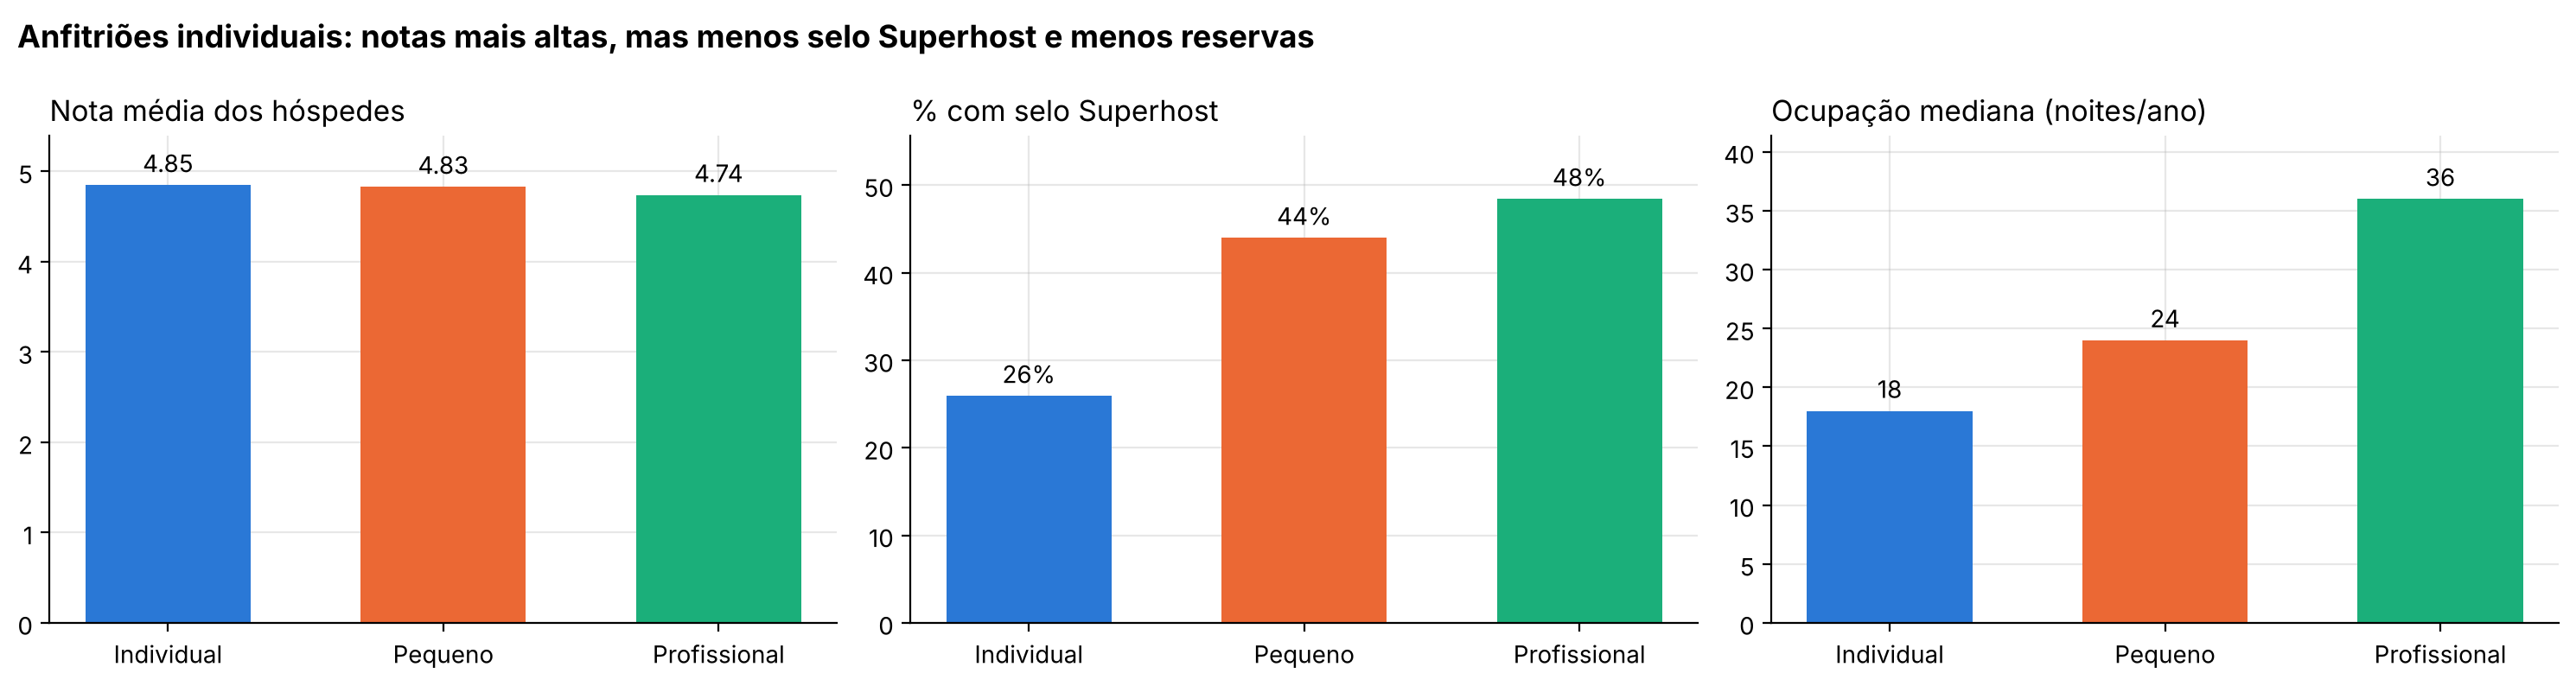

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cores = [CORES[t] for t in ordem]
rotulos = ['Individual', 'Pequeno', 'Profissional']
graficos = [('Nota média', 'Nota média dos hóspedes', '{:.2f}'),
            ('% Superhost', '% com selo Superhost', '{:.0f}%'),
            ('Ocupação mediana (noites/ano)', 'Ocupação mediana (noites/ano)', '{:.0f}')]
for ax, (col, titulo, fmt) in zip(axes, graficos):
    barras = ax.bar(rotulos, resumo[col], color=cores, width=0.6)
    ax.set_title(titulo, loc='left', fontsize=12)
    ax.bar_label(barras, labels=[fmt.format(v) for v in resumo[col]], padding=3)
    ax.margins(y=0.15)
axes[0].set_ylim(0, 5.4)
plt.suptitle('Anfitriões individuais: notas mais altas, mas menos selo Superhost e menos reservas',
             x=0.01, ha='left', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Copacabana sozinha concentra 31.0% dos anúncios da cidade



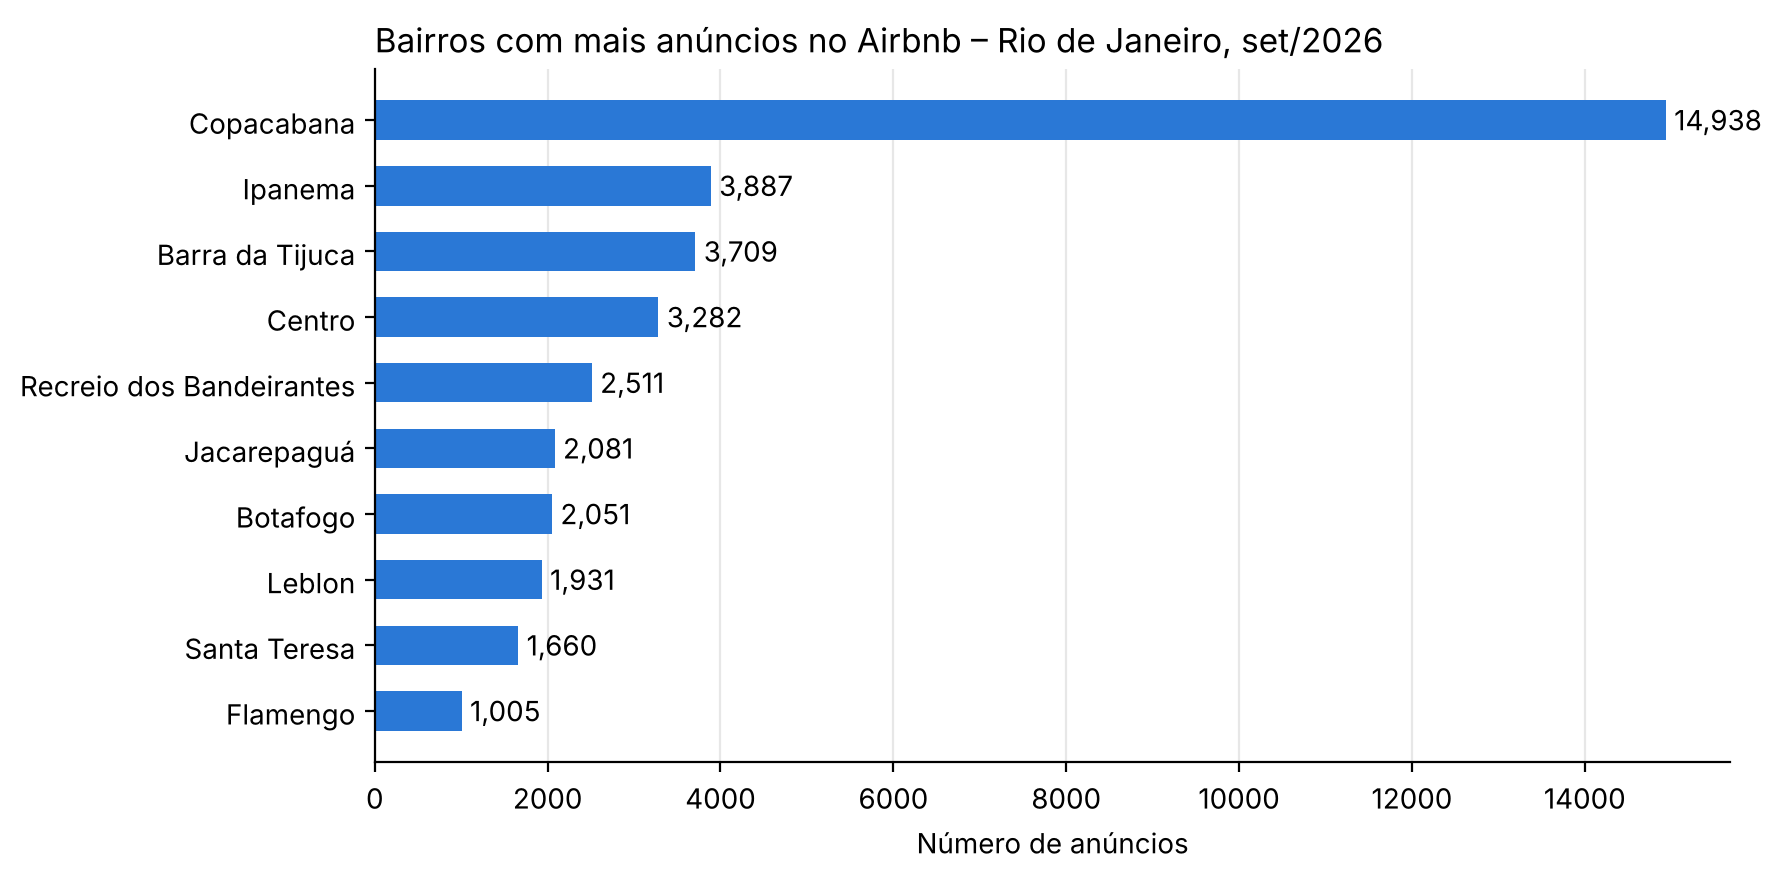

In [11]:
# Concentração geográfica
top_bairros = df['neighbourhood_cleansed'].value_counts().head(10)
print(f"Copacabana sozinha concentra {top_bairros.iloc[0] / len(df):.1%} dos anúncios da cidade\n")

fig, ax = plt.subplots(figsize=(9, 4.5))
barras = ax.barh(top_bairros.index[::-1], top_bairros.values[::-1], color='#2a78d6', height=0.6)
ax.bar_label(barras, labels=[f'{v:,}' for v in top_bairros.values[::-1]], padding=3)
ax.set_title('Bairros com mais anúncios no Airbnb – Rio de Janeiro, set/2026', loc='left', fontsize=12)
ax.set_xlabel('Número de anúncios')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

**Hipóteses levantadas na exploração**
1. Os anfitriões individuais têm **notas iguais ou melhores** que os profissionais, mas **menos reservas**. Então a diferença não parece ser de qualidade percebida pelos hóspedes.
2. Os individuais têm **muito menos selo Superhost**. Como o selo funciona como sinal de confiança, ele pode explicar parte da diferença.
3. O mercado é concentrado tanto em poucos anfitriões quanto em poucos bairros, principalmente Copacabana.

---
## Fase 3 – Preparação dos Dados
### 3.1 Limpeza

In [12]:
base = df.copy()
print(f'Início: {len(base):,} anúncios')

# 1) Converter preço de texto para número
base['preco'] = base['price'].str.replace(r'[\$,]', '', regex=True).astype(float)

# 2) Remover linhas sem as informações essenciais para o modelo
base = base.dropna(subset=['preco', 'review_scores_rating', 'bedrooms', 'minimum_nights'])
print(f'Após remover ausentes (preço, nota, quartos, noites mínimas): {len(base):,}')

# 3) Remover preços extremos (1% mais baratos e 1% mais caros)
p01, p99 = base['preco'].quantile([0.01, 0.99])
base = base[base['preco'].between(p01, p99)]
print(f'Após remover preços extremos (fora de R$ {p01:,.0f} a R$ {p99:,.0f}): {len(base):,}')

# 4) Manter apenas hospedagem de curta duração (mínimo de até 30 noites)
base = base[base['minimum_nights'] <= 30]
print(f'Após manter mínimo de até 30 noites: {len(base):,}')

Início: 48,247 anúncios


Após remover ausentes (preço, nota, quartos, noites mínimas): 35,777
Após remover preços extremos (fora de R$ 100 a R$ 4,297): 35,067
Após manter mínimo de até 30 noites: 34,997


### 3.2 Transformação (criação de variáveis – *feature engineering*)

In [13]:
# Selo Superhost como 0/1
base['superhost'] = (base['host_is_superhost'] == 't').astype(int)

# Preço em log: diminui o peso dos imóveis muito caros e deixa a relação mais linear
base['log_preco'] = np.log(base['preco'])

# Bairro: os 15 com mais anúncios e o resto agrupado em 'Outros'
top15 = base['neighbourhood_cleansed'].value_counts().head(15).index
base['bairro'] = np.where(base['neighbourhood_cleansed'].isin(top15), base['neighbourhood_cleansed'], 'Outros')

base[['preco', 'log_preco', 'superhost', 'bairro', 'tipo_anfitriao']].head()

,preco,log_preco,superhost,bairro,tipo_anfitriao
0,513.00,6.24,1,Copacabana,Individual (1 anúncio)
1,422.00,6.05,1,Copacabana,Individual (1 anúncio)
2,366.00,5.90,1,Copacabana,Individual (1 anúncio)
3,"3,761.43",8.23,1,Ipanema,Pequeno (2 a 5)
4,"1,173.25",7.07,0,Copacabana,Pequeno (2 a 5)


### 3.3 Formatação para o algoritmo

In [14]:
variaveis = ['tipo_anfitriao', 'superhost', 'review_scores_rating', 'log_preco',
             'room_type', 'bairro', 'accommodates', 'bedrooms', 'minimum_nights']
# OBS: 'number_of_reviews' fica de fora de propósito (a ocupação foi estimada a partir dele)

# Variáveis categóricas viram colunas 0/1 (one-hot encoding).
# A categoria de referência do tipo de anfitrião é 'Individual (1 anúncio)'.
X = pd.get_dummies(base[variaveis], drop_first=True, dtype=float)
y = base['estimated_occupancy_l365d']

print(f'Base final para modelagem: {X.shape[0]:,} anúncios e {X.shape[1]} variáveis')

Base final para modelagem: 34,997 anúncios e 26 variáveis


---
## Fase 4 – Modelagem
### 4.1 Desenho do teste: treino/teste, baseline e métricas
- 80% treino / 20% teste (`random_state=42`).
- **Baseline:** um "modelo" que chuta a ocupação média para todos. Qualquer modelo útil precisa superá-lo.
- **Métricas:** R² (fração da variação explicada), MAE (erro médio em noites/ano) e RMSE (pesa mais os erros grandes).

In [15]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_squared_error

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42)

modelos = {
    'Baseline (média)': DummyRegressor(strategy='mean'),
    'Regressão linear': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=42),
}
resultados = {}
for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    prev = modelo.predict(X_teste)
    resultados[nome] = {'R² treino': r2_score(y_treino, modelo.predict(X_treino)),
                        'R² teste': r2_score(y_teste, prev),
                        'MAE teste': mean_absolute_error(y_teste, prev),
                        'RMSE teste': mean_squared_error(y_teste, prev) ** 0.5}
reg, rf = modelos['Regressão linear'], modelos['Random Forest']
pd.DataFrame(resultados).T.round(3)

,R² treino,R² teste,MAE teste,RMSE teste
Baseline (média),0.00,-0.00,64.34,76.73
Regressão linear,0.28,0.28,50.61,64.89
Random Forest,0.69,0.47,41.25,55.81


### 4.2 Validação cruzada (o resultado depende do sorteio?)

In [16]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_lr = cross_val_score(LinearRegression(), X, y, cv=kf, scoring='r2')
cv_rf = cross_val_score(RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42),
                        X, y, cv=kf, scoring='r2')
print('Regressão linear  R² por rodada:', cv_lr.round(3), f'| média {cv_lr.mean():.3f} ± {cv_lr.std():.3f}')
print('Random Forest     R² por rodada:', cv_rf.round(3), f'| média {cv_rf.mean():.3f} ± {cv_rf.std():.3f}')

Regressão linear  R² por rodada: [0.285 0.281 0.275 0.295 0.283] | média 0.284 ± 0.006
Random Forest     R² por rodada: [0.471 0.481 0.454 0.476 0.468] | média 0.470 ± 0.009


### 4.2b Refinamento: ajuste de hiperparâmetros da Random Forest
Busca em grade com validação cruzada (3 partes), só na amostra de treino.

In [17]:
from sklearn.model_selection import GridSearchCV
busca = GridSearchCV(RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42),
                     {'min_samples_leaf': [1, 5, 10, 20], 'max_features': [1.0, 0.5, 'sqrt']},
                     cv=KFold(n_splits=3, shuffle=True, random_state=42), scoring='r2')
busca.fit(X_treino, y_treino)
grade = (pd.DataFrame(busca.cv_results_)[['param_min_samples_leaf', 'param_max_features', 'mean_test_score']]
         .sort_values('mean_test_score', ascending=False).round(3))
display(grade.head(5))
rf_ajustada = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42, **busca.best_params_).fit(X_treino, y_treino)
prev_aj = rf_ajustada.predict(X_teste)
print('Melhores parâmetros:', busca.best_params_)
print(f'R² teste: {r2_score(y_teste, prev_aj):.3f} | MAE: {mean_absolute_error(y_teste, prev_aj):.1f} | '
      f'R² treino: {r2_score(y_treino, rf_ajustada.predict(X_treino)):.3f}')

,param_min_samples_leaf,param_max_features,mean_test_score
5,5,0.50,0.47
6,10,0.50,0.47
9,5,sqrt,0.47
7,20,0.50,0.47
2,10,1.00,0.47


Melhores parâmetros: {'max_features': 0.5, 'min_samples_leaf': 5}


R² teste: 0.482 | MAE: 41.0 | R² treino: 0.662


### 4.3 Coeficientes com intervalo de confiança (statsmodels)
Mesma regressão, agora com intervalo de confiança de 95% e p-valor. Erros-padrão robustos (HC1).

In [18]:
import statsmodels.api as sm
ols = sm.OLS(y_treino, sm.add_constant(X_treino)).fit(cov_type='HC1')
ic = ols.conf_int()
tabela_coef = pd.DataFrame({'Efeito (noites/ano)': ols.params, 'IC 95% inf.': ic[0],
                            'IC 95% sup.': ic[1], 'p-valor': ols.pvalues}).drop('const')
tabela_coef.round(3)

,Efeito (noites/ano),IC 95% inf.,IC 95% sup.,p-valor
superhost,61.96,60.25,63.66,0.00
review_scores_rating,10.69,9.27,12.11,0.00
log_preco,-33.10,-34.59,-31.63,0.00
accommodates,3.02,2.48,3.55,0.00
bedrooms,0.01,-1.22,1.24,0.99
minimum_nights,-1.93,-2.57,-1.28,0.00
tipo_anfitriao_Pequeno (2 a 5),-0.57,-2.45,1.31,0.55
tipo_anfitriao_Profissional (6 ou mais),-1.18,-3.20,0.85,0.26
room_type_Hotel room,-35.10,-62.31,-7.88,0.01
room_type_Private room,-30.68,-32.94,-28.42,0.00


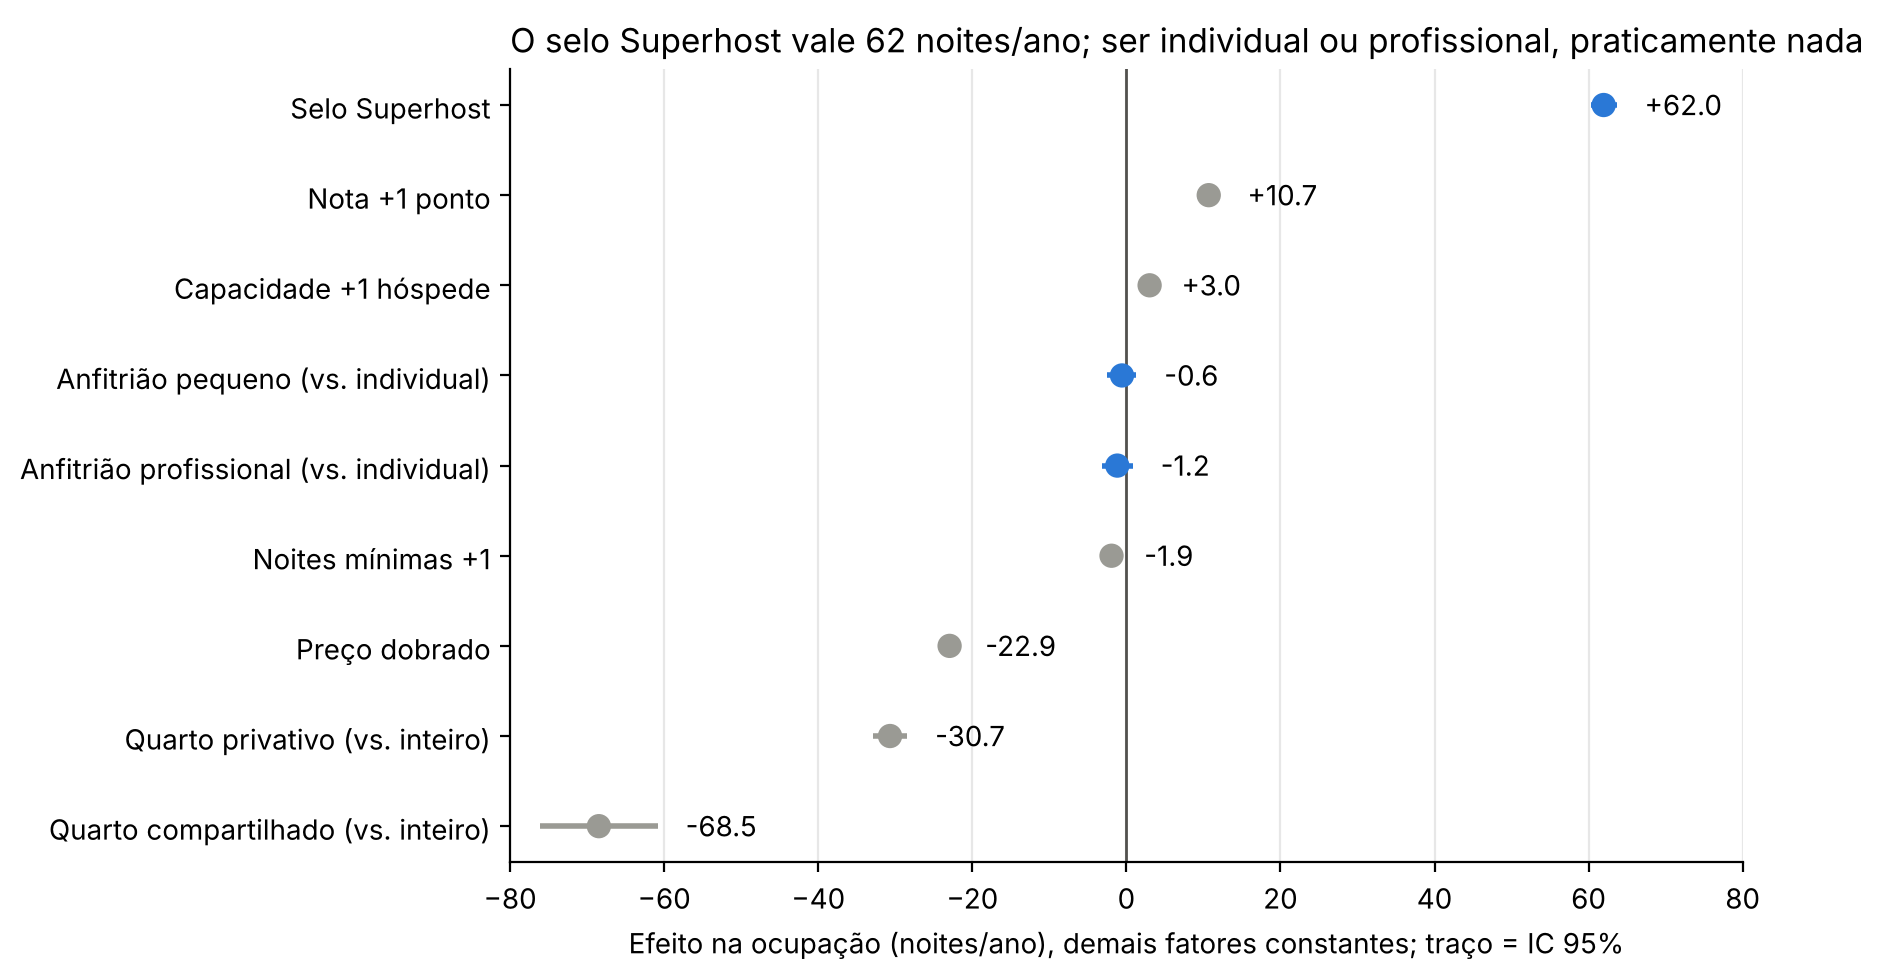

In [19]:
# Gráfico dos principais efeitos (preço convertido para "preço dobrado" = coef × ln 2)
principais = {'superhost': 'Selo Superhost', 'review_scores_rating': 'Nota +1 ponto',
              'accommodates': 'Capacidade +1 hóspede',
              'tipo_anfitriao_Pequeno (2 a 5)': 'Anfitrião pequeno (vs. individual)',
              'tipo_anfitriao_Profissional (6 ou mais)': 'Anfitrião profissional (vs. individual)',
              'minimum_nights': 'Noites mínimas +1', 'log_preco': 'Preço dobrado',
              'room_type_Private room': 'Quarto privativo (vs. inteiro)',
              'room_type_Shared room': 'Quarto compartilhado (vs. inteiro)'}
g = tabela_coef.loc[list(principais)].copy()
g.loc['log_preco', ['Efeito (noites/ano)', 'IC 95% inf.', 'IC 95% sup.']] *= np.log(2)
g = g.rename(index=principais).sort_values('Efeito (noites/ano)')
destaque = ['Selo Superhost', 'Anfitrião pequeno (vs. individual)', 'Anfitrião profissional (vs. individual)']

fig, ax = plt.subplots(figsize=(9, 5))
cores_g = ['#2a78d6' if i in destaque else '#9a9a94' for i in g.index]
ax.errorbar(g['Efeito (noites/ano)'], g.index,
            xerr=[g['Efeito (noites/ano)'] - g['IC 95% inf.'], g['IC 95% sup.'] - g['Efeito (noites/ano)']],
            fmt='none', ecolor=cores_g, elinewidth=2)
ax.scatter(g['Efeito (noites/ano)'], g.index, color=cores_g, s=60, zorder=3)
for v, sup, nome in zip(g['Efeito (noites/ano)'], g['IC 95% sup.'], g.index):
    ax.annotate(f'{v:+.1f}', (max(v, sup), nome), xytext=(10, 0), textcoords='offset points', va='center')
ax.axvline(0, color='#52514e', linewidth=1)
ax.set_xlim(-80, 80)
ax.set_xlabel('Efeito na ocupação (noites/ano), demais fatores constantes; traço = IC 95%')
ax.set_title('O selo Superhost vale 62 noites/ano; ser individual ou profissional, praticamente nada',
             loc='left', fontsize=12)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

### 4.4 Teste da hipótese central: o tipo de anfitrião com e sem o selo
Três versões da regressão na base completa, acrescentando variáveis aos poucos.

In [20]:
tipo_cols = [c for c in X.columns if c.startswith('tipo_anfitriao')]
versoes = {'A. Só o tipo de anfitrião': X[tipo_cols],
           'B. Tudo, menos o selo': X.drop(columns='superhost'),
           'C. Tudo, com o selo': X}
linhas = {}
for nome, Xv in versoes.items():
    m = sm.OLS(y, sm.add_constant(Xv)).fit(cov_type='HC1')
    ci = m.conf_int()
    linhas[nome] = {
        'Profissional vs. individual': f"{m.params[tipo_cols[1]]:+.1f} ({ci.loc[tipo_cols[1], 0]:.1f} a {ci.loc[tipo_cols[1], 1]:.1f})",
        'Pequeno vs. individual': f"{m.params[tipo_cols[0]]:+.1f} ({ci.loc[tipo_cols[0], 0]:.1f} a {ci.loc[tipo_cols[0], 1]:.1f})",
        'R²': round(m.rsquared, 3)}
pd.DataFrame(linhas).T

,Profissional vs. individual,Pequeno vs. individual,R²
A. Só o tipo de anfitrião,+16.3 (14.3 a 18.2),+10.0 (8.1 a 12.0),0.01
"B. Tudo, menos o selo",+12.3 (10.4 a 14.2),+12.2 (10.3 a 14.1),0.15
"C. Tudo, com o selo",-0.7 (-2.5 a 1.1),+0.6 (-1.1 a 2.3),0.28


In [21]:
# Robustez: só individuais estritos (um único anúncio no Airbnb inteiro, não só no Rio)
estrito = base[~((base['calculated_host_listings_count'] == 1) & (df.loc[base.index, 'host_listings_count'] > 1))]
Xe = pd.get_dummies(estrito[variaveis], drop_first=True, dtype=float)
ye = estrito['estimated_occupancy_l365d']
col = 'tipo_anfitriao_Profissional (6 ou mais)'
for nome, Xv in {'A. Só o tipo': Xe[[c for c in Xe.columns if c.startswith('tipo_anfitriao')]], 'C. Completo': Xe}.items():
    m = sm.OLS(ye, sm.add_constant(Xv)).fit(cov_type='HC1')
    print(f"{nome}: profissional vs. individual estrito = {m.params[col]:+.1f} "
          f"(IC {m.conf_int().loc[col, 0]:.1f} a {m.conf_int().loc[col, 1]:.1f}) | n = {len(estrito):,}")

A. Só o tipo: profissional vs. individual estrito = +18.0 (IC 16.0 a 20.1) | n = 32,974
C. Completo: profissional vs. individual estrito = -0.2 (IC -2.1 a 1.6) | n = 32,974


### 4.5 Confirmação pela Random Forest e diagnóstico

In [22]:
importancia = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print('Importância (top 8):')
print((importancia.head(8) * 100).round(1).astype(str) + '%')
print(f"\nSoma das importâncias do tipo de anfitrião: {importancia[tipo_cols].sum():.1%}")

prev_reg = reg.predict(X_teste)
residuo = y_teste - prev_reg
print(f'\nResíduo médio no teste: {residuo.mean():.1f} noites')
print(f'Previsões abaixo de zero: {(prev_reg < 0).mean():.1%}')
print('Resíduo médio por faixa de ocupação real (real − previsto):')
print(residuo.groupby(pd.cut(y_teste, [-1, 0, 24, 96, 255])).mean().round(1))

Importância (top 8):
review_scores_rating                       32.9%
superhost                                  28.2%
log_preco                                  17.4%
minimum_nights                              4.5%
accommodates                                3.6%
tipo_anfitriao_Profissional (6 ou mais)     2.2%
bairro_Copacabana                           1.9%
tipo_anfitriao_Pequeno (2 a 5)              1.8%
dtype: str

Soma das importâncias do tipo de anfitrião: 4.1%

Resíduo médio no teste: -0.7 noites
Previsões abaixo de zero: 2.9%
Resíduo médio por faixa de ocupação real (real − previsto):
estimated_occupancy_l365d
(-1, 0]     -37.10
(0, 24]     -40.80
(24, 96]    -23.90
(96, 255]    69.40
Name: estimated_occupancy_l365d, dtype: float64


**Leitura da Fase 4**
- Os dois modelos superam o baseline e a meta (R² ≥ 0,25) e são estáveis na validação cruzada.
- A Random Forest prevê melhor, mas sobreajusta (R² de treino bem maior que o de teste). Por isso usamos dela só o teste e as importâncias.
- **Hipótese central confirmada:** a vantagem dos profissionais (+16 noites/ano sem controles) **desaparece** quando o selo Superhost entra no modelo. O tipo de anfitrião, sozinho, explica cerca de 1% da variação.

---
## Fase 5 – Avaliação
### 5.1 Verificação extra: por que os individuais não têm o selo?
A regra oficial do Superhost ([central de ajuda do Airbnb](https://www.airbnb.com/help/article/829)), medida nos últimos 12 meses: **10+ reservas** (ou 3 somando 100 noites), nota **≥ 4,8**, menos de 1% de cancelamentos e 90% de resposta em 24h.

Usamos as avaliações dos últimos 12 meses (`number_of_reviews_ltm`) como aproximação das estadias. É um limite inferior, já que nem todo hóspede avalia.

In [23]:
df['superhost_flag'] = df['host_is_superhost'] == 't'
individual = df['calculated_host_listings_count'] == 1
bem_avaliado = df['review_scores_rating'] >= 4.8

comparacao_sh = (df[individual & bem_avaliado]
                 .groupby('superhost_flag')
                 .agg(anuncios=('id', 'count'),
                      nota_media=('review_scores_rating', 'mean'),
                      avaliacoes_ano_mediana=('number_of_reviews_ltm', 'median'),
                      ocupacao_mediana=('estimated_occupancy_l365d', 'median')))
comparacao_sh.index = ['Sem selo', 'Com selo']
display(comparacao_sh.round(2))

sem_selo = df[individual & bem_avaliado & ~df['superhost_flag']]
print(f"Individuais com nota ≥ 4,8 e sem selo: {len(sem_selo):,}")
print(f"  com menos de 10 avaliações no ano: {(sem_selo['number_of_reviews_ltm'] < 10).mean():.0%}")
print(f"  sem nenhuma avaliação no ano:      {(sem_selo['number_of_reviews_ltm'] == 0).mean():.0%}")

# Contraprova: entre quem já tem volume (10+ avaliações no ano) e nota ≥ 4,8, quem tem o selo?
com_volume = df[(df['number_of_reviews_ltm'] >= 10) & bem_avaliado]
print('\n% com selo entre anúncios com volume e nota ≥ 4,8:')
print(com_volume.groupby(individual.loc[com_volume.index].map({True: 'Individual', False: 'Demais'}))['superhost_flag']
      .mean().map('{:.0%}'.format))

,anuncios,nota_media,avaliacoes_ano_mediana,ocupacao_mediana
Sem selo,7896,4.96,2.00,12.00
Com selo,4797,4.93,19.00,120.00


Individuais com nota ≥ 4,8 e sem selo: 7,896
  com menos de 10 avaliações no ano: 85%
  sem nenhuma avaliação no ano:      21%

% com selo entre anúncios com volume e nota ≥ 4,8:


calculated_host_listings_count
Demais        82%
Individual    77%
Name: superhost_flag, dtype: str


**Conclusão da verificação:** os individuais sem selo têm nota **maior** que os com selo. O que falta é **volume**: 85% tiveram menos de 10 avaliações no ano. Quando chegam ao volume, ganham o selo quase na mesma proporção que os demais (77% contra 82%). A relação selo ↔ ocupação é **circular**, e a ação certa é dar as **primeiras reservas** a quem já tem nota de Superhost.

### 5.2 Critérios de sucesso

| Tipo | Critério (Fase 1) | Resultado | Veredito |
|---|---|---|---|
| Negócio | Explicar por que os individuais têm menos reservas | barreira de volume para o selo (4.4 e 5.1) | Atingido |
| Negócio | Propor ação acionável | programa "Anfitrião Carioca" com público de 4.845 anúncios (Fase 6) | Atingido |
| Negócio | Resultado acompanhável | 4 indicadores com linha de base | Atingido |
| Dados | Medir a concentração | 42% individuais; 1% maior controla 17%; Copacabana 31% | Atingido |
| Dados | R² ≥ 0,25 no teste | regressão 0,29; Random Forest 0,47 | Atingido |
| Dados | Comparar algoritmos | baseline, regressão, Random Forest | Atingido |

**Limites:** associação, não causa; ocupação estimada a partir de avaliações (teto de 255 noites); uma única coleta (set/2026); só anúncios com ao menos uma avaliação.

**Decisão:** seguir para a implantação em formato de **piloto com grupo de controle**, que é o que responde à pergunta causal.

---
## Impacto social e inovação na estratégia de Marketing Digital

**Necessidade social:** acesso de pequenos empreendedores ao mercado digital. O anfitrião individual entrega qualidade de Superhost, mas fica preso numa regra que exige volume para dar visibilidade.

| Público | Benefício esperado | Risco | Medida |
|---|---|---|---|
| Anfitriões individuais (42% dos anúncios) | mais reservas e renda; acesso ao selo | o programa não gerar reservas | piloto com grupo de controle |
| Moradores dos bairros turísticos | renda do turismo fica com famílias do bairro | mais imóveis inteiros saírem do mercado de moradia | prioridade a quartos na casa do anfitrião; limite de vagas para imóveis inteiros |
| Hóspedes com deficiência (barreira de acesso) | encontrar hospedagem adequada | informação seguir inexistente | itens de acessibilidade obrigatórios para participar |

**Ação de inovação social.**
> Para enfrentar a **barreira de volume que impede anfitriões individuais bem avaliados de alcançar o selo Superhost**, propomos o programa **"Anfitrião Carioca"**: um selo de entrada e um impulso temporário de visibilidade na busca, até completar 10 estadias, para quem tem um único anúncio, nota ≥ 4,8 e itens de acessibilidade preenchidos. A divulgação será feita **na busca do Airbnb, em e-mail aos elegíveis e nas redes sociais do Airbnb Brasil**, com foco em **microempreendedores cariocas**. A ação pode contribuir para **mais diversidade de oferta e confiança dos hóspedes** e gerar **renda para famílias do Rio e informação de acessibilidade para hóspedes com deficiência**. Para reduzir o **risco de captura por gestores profissionais e de perda de moradia**, adotaremos **o limite de um anúncio verificado por documento e a prioridade para quartos na casa do anfitrião**.

In [24]:
# Linha de base dos indicadores (set/2026)
amen = df['amenities'].fillna('[]').apply(json.loads)
acessivel = amen.apply(lambda lista: any(k in a.lower() for a in lista
                                         for k in ['wheelchair', 'step-free', 'accessible', 'grab bar', 'single level']))
ind_df = df[individual]
linha_base = pd.DataFrame({
    'Indicador': ['% que atinge 10 estadias no ano, entre individuais bem avaliados sem selo (mudança para o público; ver o público do piloto na Fase 6)',
                  '% dos anfitriões individuais com selo Superhost',
                  'Diferença de ocupação mediana (profissional − individual), noites/ano',
                  '% de anúncios com informação de acessibilidade'],
    'Linha de base (set/2026)': [
        round((sem_selo['number_of_reviews_ltm'] >= 10).mean() * 100, 1),
        round(ind_df['superhost_flag'].mean() * 100, 1),
        df.loc[df['calculated_host_listings_count'] >= 6, 'estimated_occupancy_l365d'].median()
            - ind_df['estimated_occupancy_l365d'].median(),
        round(acessivel.mean() * 100, 1)],
    'Quando medir': ['fim de cada trimestre do piloto, vs. grupo de controle',
                     'a cada coleta trimestral', 'a cada coleta trimestral', 'a cada coleta trimestral']})
linha_base

,Indicador,Linha de base (set/2026),Quando medir
0,"% que atinge 10 estadias no ano, entre individ...",15.10,"fim de cada trimestre do piloto, vs. grupo de ..."
1,% dos anfitriões individuais com selo Superhost,25.90,a cada coleta trimestral
2,Diferença de ocupação mediana (profissional − ...,18.00,a cada coleta trimestral
3,% de anúncios com informação de acessibilidade,3.50,a cada coleta trimestral


*O primeiro indicador é um **resultado esperado** (só será observado depois do piloto). Os outros três já têm linha de base **observada**.*

---
## Fase 6 – Implantação
### 6.1 Como o modelo entra na operação: o público do piloto
Público = anúncios individuais, sem selo, nota ≥ 4,8 e **ocupação abaixo da prevista** pela regressão.

In [25]:
reg_completo = LinearRegression().fit(X, y)
base['ocupacao_prevista'] = reg_completo.predict(X)
publico = base[(base['calculated_host_listings_count'] == 1) & (base['superhost'] == 0)
               & (base['review_scores_rating'] >= 4.8)
               & (base['estimated_occupancy_l365d'] < base['ocupacao_prevista'])]
print(f'Anúncios no público do piloto: {len(publico):,}')
print(f"Ocupação mediana real: {publico['estimated_occupancy_l365d'].median():.0f} noites/ano | "
      f"prevista: {publico['ocupacao_prevista'].median():.0f}")
print(f"Quartos na casa do anfitrião: {(publico['room_type'] == 'Private room').sum():,}")
print(f"Linha de base do indicador principal no público do piloto (10+ avaliações no ano): {(publico['number_of_reviews_ltm'] >= 10).mean():.1%}")
print('\nBairros com mais anúncios no público:')
print(publico['bairro'].value_counts().head(5))

# Sorteio dos grupos (programa x controle), com semente fixa
publico = publico.assign(grupo=np.where(np.random.default_rng(42).random(len(publico)) < 0.5, 'Programa', 'Controle'))
publico.groupby('grupo')[['review_scores_rating', 'preco', 'estimated_occupancy_l365d']].median().round(2)

Anúncios no público do piloto: 4,845
Ocupação mediana real: 12 noites/ano | prevista: 49
Quartos na casa do anfitrião: 616
Linha de base do indicador principal no público do piloto (10+ avaliações no ano): 2.1%

Bairros com mais anúncios no público:
bairro
Copacabana         1367
Outros              721
Barra da Tijuca     368
Centro              358
Ipanema             303
Name: count, dtype: int64


,review_scores_rating,preco,estimated_occupancy_l365d
grupo,,,
Controle,5.00,455.00,12.00
Programa,5.00,460.00,12.00


### 6.2 Etapas
1. **Preparação:** selecionar o público acima e sortear metade para o programa e metade para controle. *Passagem:* grupos parecidos em nota, preço e bairro (tabela acima).
2. **Piloto (duas avaliações trimestrais do selo):** o grupo do programa recebe impulso de visibilidade e selo de entrada; o controle segue com a busca atual. *Passagem:* o programa supera o controle em estadias, sem aumento de imóveis inteiros. Se não, ajustar a regra ou encerrar.
3. **Expansão:** abrir para todos os individuais elegíveis do Rio e avaliar outras cidades.
4. **Rotina:** indicadores a cada coleta trimestral do Inside Airbnb; refazer o modelo se o R² cair abaixo de 0,25.

### 6.3 Monitoramento e documentação
Rodar este notebook a cada nova coleta trimestral. Ele refaz todos os números com sementes fixas. Gatilhos: indicador piorando por 2 trimestres → revisar o programa; R² < 0,25 → voltar à Fase 1; colunas renomeadas ou vazias → ajustar a Fase 3; mudança na regra do selo → refazer a verificação 5.1.

---
## Considerações finais
- **Problema:** os anfitriões individuais têm 42% dos anúncios e nota igual ou maior, mas metade das reservas.
- **Observado nos dados:** com os outros fatores constantes, ser individual não reduz a ocupação. A diferença está no selo Superhost, que exige 10 estadias por ano, e 85% dos individuais bem avaliados sem selo não chegam lá.
- **Decisão:** programa "Anfitrião Carioca", com visibilidade inicial para quem já tem nota de Superhost, regras contra a captura e a perda de moradia, e acessibilidade obrigatória.
- **Esperado, ainda a verificar:** se a visibilidade inicial **causa** mais reservas. É o que o piloto com grupo de controle vai medir.

> O modelo mudou a pergunta de "os pequenos são piores?" para "os pequenos conseguem começar?".